In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

In [2]:
# Descargar datos de un activo: COCA-COLA (KO), para los ultimos 10 años
ko = yf.download("KO", period="10y", interval="1d", multi_level_index=False)
ko

[*********************100%***********************]  1 of 1 completed


,Close,High,Low,Open,Volume
Date,,,,,
2016-09-19,30.878319,31.076351,30.863652,30.922327,7659900
2016-09-20,31.054361,31.193716,30.981017,31.032359,8407200
2016-09-21,31.193716,31.252394,30.878331,31.010353,13654700
2016-09-22,31.509100,31.545772,31.311068,31.325737,9288300
2016-09-23,31.347740,31.494428,31.281729,31.399082,8852700
...,...,...,...,...,...
2026-09-11,87.766289,88.124154,87.289133,87.915401,9988700
2026-09-14,88.820000,89.824011,88.342851,89.466146,14066100
2026-09-15,88.709999,88.900002,87.800003,88.529999,13148900


In [3]:
ko = ko.reset_index()

In [4]:
ko

,Date,Close,High,Low,Open,Volume
0,2016-09-19,30.878319,31.076351,30.863652,30.922327,7659900
1,2016-09-20,31.054361,31.193716,30.981017,31.032359,8407200
2,2016-09-21,31.193716,31.252394,30.878331,31.010353,13654700
3,2016-09-22,31.509100,31.545772,31.311068,31.325737,9288300
4,2016-09-23,31.347740,31.494428,31.281729,31.399082,8852700
...,...,...,...,...,...,...
2508,2026-09-11,87.766289,88.124154,87.289133,87.915401,9988700
2509,2026-09-14,88.820000,89.824011,88.342851,89.466146,14066100
2510,2026-09-15,88.709999,88.900002,87.800003,88.529999,13148900
2511,2026-09-16,87.870003,88.660004,87.739998,88.480003,17074800


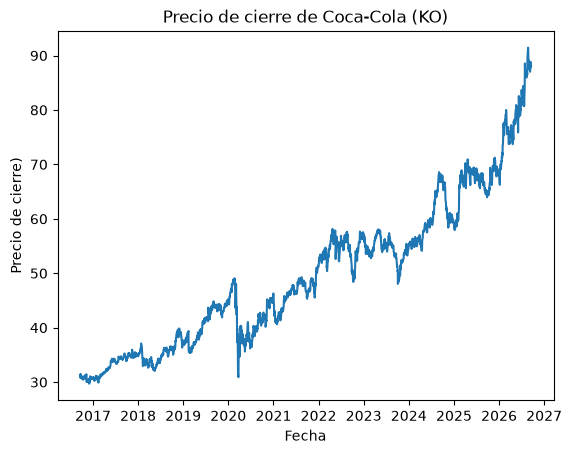

In [5]:
# Representa gráficamente los datos del precio de cierre

plt.plot(ko["Date"], ko["Close"])

plt.title("Precio de cierre de Coca-Cola (KO)")
plt.xlabel("Fecha")
plt.ylabel("Precio de cierre)")
plt.show()

In [6]:
# Calcula y representa la rentabilidad diaria del activo
ko["Rentabilidad"] = ko["Close"].pct_change() #Pt - Pt-1/Pt-1
ko

,Date,Close,High,Low,Open,Volume,Rentabilidad
0,2016-09-19,30.878319,31.076351,30.863652,30.922327,7659900,NaN
1,2016-09-20,31.054361,31.193716,30.981017,31.032359,8407200,0.005701
2,2016-09-21,31.193716,31.252394,30.878331,31.010353,13654700,0.004487
3,2016-09-22,31.509100,31.545772,31.311068,31.325737,9288300,0.010110
4,2016-09-23,31.347740,31.494428,31.281729,31.399082,8852700,-0.005121
...,...,...,...,...,...,...,...
2508,2026-09-11,87.766289,88.124154,87.289133,87.915401,9988700,0.005237
2509,2026-09-14,88.820000,89.824011,88.342851,89.466146,14066100,0.012006
2510,2026-09-15,88.709999,88.900002,87.800003,88.529999,13148900,-0.001238
2511,2026-09-16,87.870003,88.660004,87.739998,88.480003,17074800,-0.009469


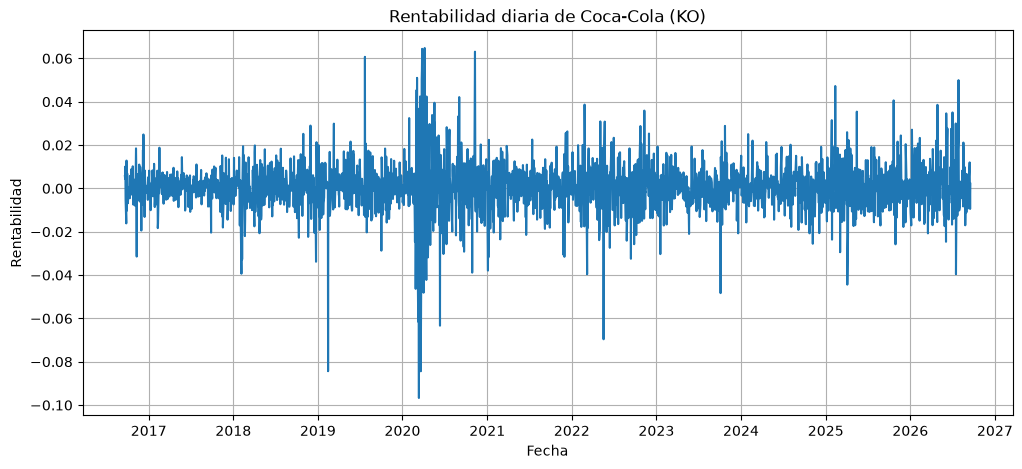

In [7]:
plt.figure(figsize=(12, 5))
plt.plot(ko["Date"], ko["Rentabilidad"])

plt.title("Rentabilidad diaria de Coca-Cola (KO)")
plt.xlabel("Fecha")
plt.ylabel("Rentabilidad")
plt.grid()
plt.show()

Define la función de **rentabilidad anualizada**:
$r_{periodo} = (1+r)^n -1$

In [8]:
# Función para calcular rentabilidades anualizadas
def rtb_anualizada(tipo, n, p0, p1, dias_habiles):
    if tipo == 'd': #intervalos diarios
        r=(p1-p0)/p0
        return ((1+r)**(dias_habiles/n)) -1
    if tipo == 'm': #intervalos mensuales
        r=(p1-p0)/p0
        return ((1+r)**(12/n)) -1
    if tipo == 'y':#intervalos anuales
            r=(p1-p0)/p0
            return ((1+r)**(1/n)) -1
    else:
         print("Por favor introduzca 'd', 'm' o 'y' en el tipo")
         return


In [9]:
# Calcula la rentabilidad media, la rentabilidad activa y la rentabilidad anual del periodo.
Retabilidad_media = ko['Rentabilidad'].mean()
print(Retabilidad_media)
print(Retabilidad_media*100)

0.00048488961708205127
0.048488961708205124


In [10]:
#rentabilidad activa
p0 = ko["Close"].iloc[0]
p1 = ko["Close"].iloc[-1]


# Rentabilidad activa del periodo
rentabilidad_activa = (p1 - p0) / p0
rentabilidad_activa

np.float64(1.8518391226904567)

In [11]:
#rentabilidad anual
dias_habiles = len(ko)
rentabilidad_anual = rtb_anualizada(
    'd',
    10,
    p0,
    p1,
    dias_habiles
)
rentabilidad_anual

np.float64(2.3600334922311495e+114)

In [12]:
# Calcula la volatilidad del activo financiero.
volatilidad_diaria = ko["Rentabilidad"].std()

print(volatilidad_diaria)

0.01160620135569644


**Volatilidad anualizada**: $\sigma\sqrt{n}$

In [13]:
# Anualiza la volatilidad (desviación)
volatilidad_anual = volatilidad_diaria * (252 ** 0.5)

print(volatilidad_anual * 100, "%") #volatilidad baja (<20 se considera bajo)

18.42427347198809 %


In [14]:
# Hay veces que es interesante ver como va evolucionando la volatilidad de un activo. Calcula la secuencia de volatilidades a 30 días.
# Volatilidad móvil a 30 días
ko["Volatilidad_30d"] = ko["Rentabilidad"].rolling(window=30).std()

ko = ko.dropna(subset=["Volatilidad_30d"])
ko[["Date", "Rentabilidad", "Volatilidad_30d"]].head(35)  

,Date,Rentabilidad,Volatilidad_30d
30,2016-10-31,0.004025,0.006449
31,2016-11-01,-0.006604,0.006482
32,2016-11-02,-0.001662,0.006428
33,2016-11-03,-0.000476,0.006116
34,2016-11-04,-0.008089,0.006213
35,2016-11-07,0.018469,0.006476
36,2016-11-08,0.009892,0.006299
37,2016-11-09,-0.014226,0.006560
38,2016-11-10,-0.031464,0.008728
39,2016-11-11,0.002198,0.008626


**Ratio de Sharpe**: $S_h = \frac{r-r_f}{\sigma}$

In [15]:
# Tasa libre de riesgo
rf = 0.01

# Volatilidad
sigma = ko["Rentabilidad"].std()

# Ratio de Sharpe
sharpe = (rentabilidad_activa - rf) / sigma

print(sharpe)

158.05485675796805


$Drawdown_i = \frac{p_i}{p_{max}} - 1$

$Max-drawdown = min(drawdown_i)_n$

In [16]:
# DRAWDOWN
ko["P_max"] = ko["Close"].cummax() #maximo acumulado hasta el momento

# Drawdown
ko["Drawdown"] = ko["Close"] / ko["P_max"] - 1

# Max Drawdown
max_drawdown = ko["Drawdown"].min()

print(max_drawdown)

-0.3698751746599297


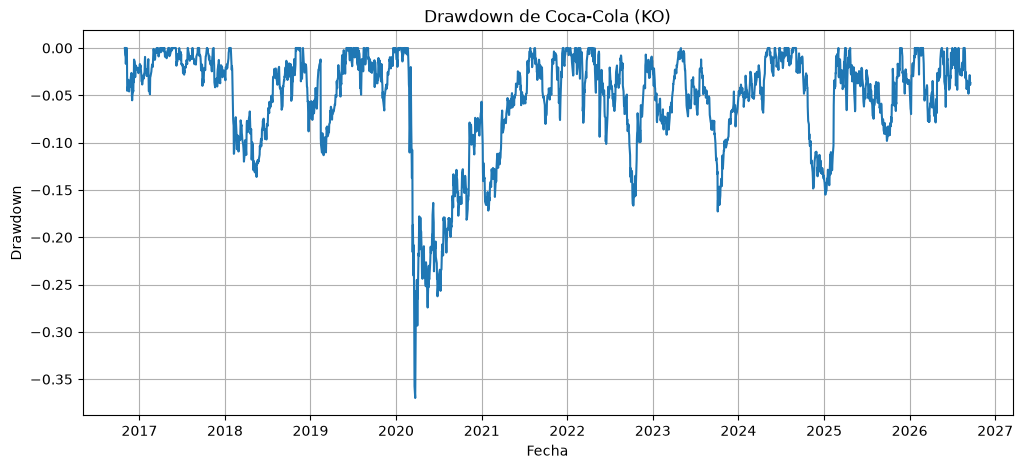

In [17]:
#Gráficar DRAWDOWN
plt.figure(figsize=(12, 5))

plt.plot(ko["Date"], ko["Drawdown"])

plt.title("Drawdown de Coca-Cola (KO)")
plt.xlabel("Fecha")
plt.ylabel("Drawdown")
plt.grid()
plt.show()